# Group A – Polynomial Regression
## Predicting a car's fuel economy (MPG) from its engine horsepower

**Dataset:** *Auto MPG* (UCI Machine Learning Repository): 398 cars built between 1970 and 1982.
Each car has its **horsepower** and its fuel economy in **miles per gallon (mpg)**.

**Question:** If I know how powerful a car's engine is, can I predict how far it goes on a gallon of fuel?

The class example fitted a polynomial to *made-up* page-speed data using `np.polyfit`. Here I use **real** data and
scikit-learn's `PolynomialFeatures` + `LinearRegression`. I also add a **train/test split**, so I can measure
overfitting properly instead of just looking at the r-squared on the training data.

### How Polynomial Regression works
Linear regression fits a straight line: $\hat{y} = b_0 + b_1x$.

Polynomial regression adds powers of the same input as extra features:

$$\hat{y} = b_0 + b_1x + b_2x^2 + \dots + b_nx^n$$

The model is still *linear in its coefficients* $b_0 \dots b_n$, so the same **least-squares** method is used.
It picks the coefficients that minimise the sum of squared errors $\sum (y - \hat{y})^2$. The only change is that
the inputs now include $x^2, x^3, \dots$, which lets the fitted line **bend**.

The **degree** $n$ controls how flexible the curve is:
* too low → **underfitting** (the curve can't follow the real shape)
* too high → **overfitting** (the curve follows the noise in the training data and generalises badly)

In [4]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error


def load_data(name):
    """Load a dataset from the local data/ folder, or download it from seaborn if not found (e.g. in Colab)."""
    for path in (f"data/{name}.csv", f"{name}.csv"):
        if os.path.exists(path):
            return pd.read_csv(path)
    return sns.load_dataset(name)

ModuleNotFoundError: No module named 'matplotlib'

### 1. Load and look at the data

In [2]:
cars = load_data("mpg")
cars = cars.dropna(subset=["horsepower"])      # 6 cars have no horsepower recorded, so drop them
print(cars.shape)
cars[["name", "horsepower", "mpg"]].head()

(392, 9)


,name,horsepower,mpg
0,chevrolet chevelle malibu,130.0,18.0
1,buick skylark 320,165.0,15.0
2,plymouth satellite,150.0,18.0
3,amc rebel sst,150.0,16.0
4,ford torino,140.0,17.0


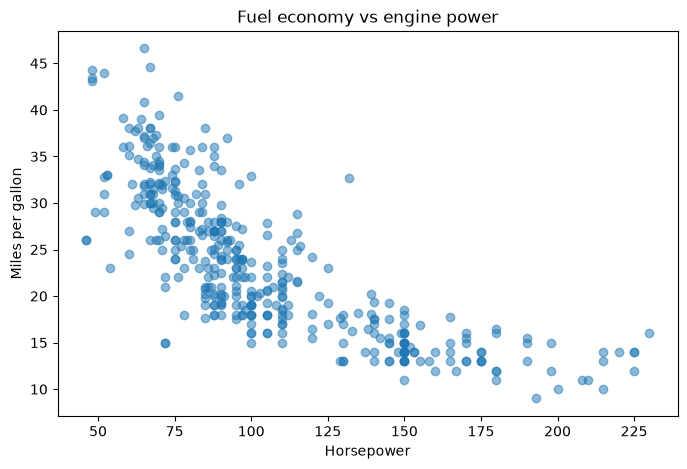

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(cars["horsepower"], cars["mpg"], alpha=0.5)
plt.xlabel("Horsepower")
plt.ylabel("Miles per gallon")
plt.title("Fuel economy vs engine power")
plt.show()

The relationship is clearly **not a straight line**. MPG drops quickly as horsepower goes from 50 to about 130,
then flattens out. Even very powerful cars don't go to 0 mpg. A straight line can't follow this curve, which
makes this a good problem for polynomial regression.

### 2. Split into training and test data
I hold back 25% of the cars as a **test set**. The model never sees them during training, so they show how
well it predicts *new* cars.

In [4]:
X = cars[["horsepower"]].values   # scikit-learn expects a 2-D array of features
y = cars["mpg"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(f"Training cars: {len(X_train)},  Test cars: {len(X_test)}")

Training cars: 294,  Test cars: 98


### 3. Build the model
A pipeline does three steps in order:
1. `PolynomialFeatures(degree)` turns each horsepower value $x$ into $[1, x, x^2, ..., x^n]$
2. `StandardScaler()` puts those columns on the same scale ($x^{10}$ is a huge number otherwise, which causes numerical problems)
3. `LinearRegression()` finds the best coefficients using least squares

In [5]:
def poly_model(degree):
    return make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())

# Start with a straight line (degree 1) and a quadratic curve (degree 2)
linear = poly_model(1).fit(X_train, y_train)
quad   = poly_model(2).fit(X_train, y_train)

for name, model in [("Degree 1 (straight line)", linear), ("Degree 2 (quadratic)", quad)]:
    pred = model.predict(X_test)
    print(f"{name:26s} test R² = {r2_score(y_test, pred):.3f}   mean error = {mean_absolute_error(y_test, pred):.2f} mpg")

Degree 1 (straight line)   test R² = 0.566   mean error = 3.78 mpg
Degree 2 (quadratic)       test R² = 0.659   mean error = 3.21 mpg


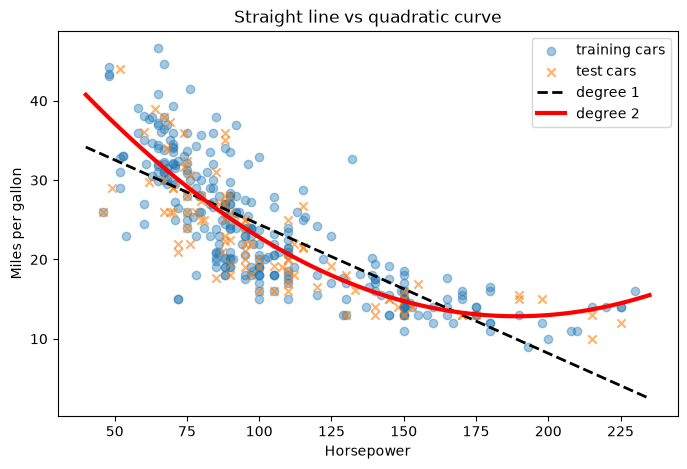

In [6]:
xp = np.linspace(40, 235, 300).reshape(-1, 1)   # smooth range of horsepower values for drawing the curves

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.4, label="training cars")
plt.scatter(X_test, y_test, alpha=0.6, marker="x", label="test cars")
plt.plot(xp, linear.predict(xp), "k--", lw=2, label="degree 1")
plt.plot(xp, quad.predict(xp), "r", lw=3, label="degree 2")
plt.xlabel("Horsepower"); plt.ylabel("Miles per gallon")
plt.legend(); plt.title("Straight line vs quadratic curve")
plt.show()

**Result:** the straight line **underfits**. It predicts too low for small engines and too low again for
big ones, and on very powerful cars it heads towards impossible values. The quadratic curve follows the bend in
the data. Test R² goes up from about **0.57 to 0.66**, and the average error goes down from about **3.8 to
3.2 mpg**.

### 4. Choosing the degree – underfitting vs overfitting
The class activity asked: *can higher orders give a better fit, and do we start to see overfitting?*
To answer this properly, I compare each degree on the **training** data and on the **unseen test** data.

 degree  train R²  test R²
      1     0.613    0.566
      2     0.693    0.659
      3     0.693    0.659
      4     0.693    0.662
      5     0.701    0.670
      6     0.703    0.675
      7     0.704    0.683
      8     0.704    0.683
      9     0.705    0.681
     10     0.705    0.683
     11     0.705    0.683
     12     0.705    0.683
     13     0.708    0.666
     14     0.708    0.670
     15     0.707    0.674


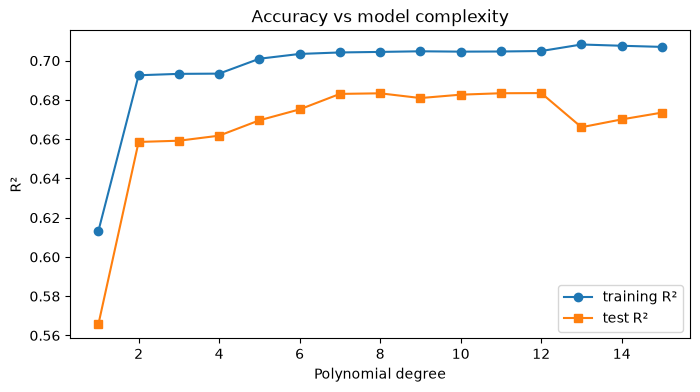

In [7]:
degrees = range(1, 16)
train_r2, test_r2 = [], []
for d in degrees:
    m = poly_model(d).fit(X_train, y_train)
    train_r2.append(r2_score(y_train, m.predict(X_train)))
    test_r2.append(r2_score(y_test, m.predict(X_test)))

results = pd.DataFrame({"degree": degrees, "train R²": train_r2, "test R²": test_r2}).round(3)
print(results.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(degrees, train_r2, "o-", label="training R²")
plt.plot(degrees, test_r2, "s-", label="test R²")
plt.xlabel("Polynomial degree"); plt.ylabel("R²"); plt.legend()
plt.title("Accuracy vs model complexity")
plt.show()

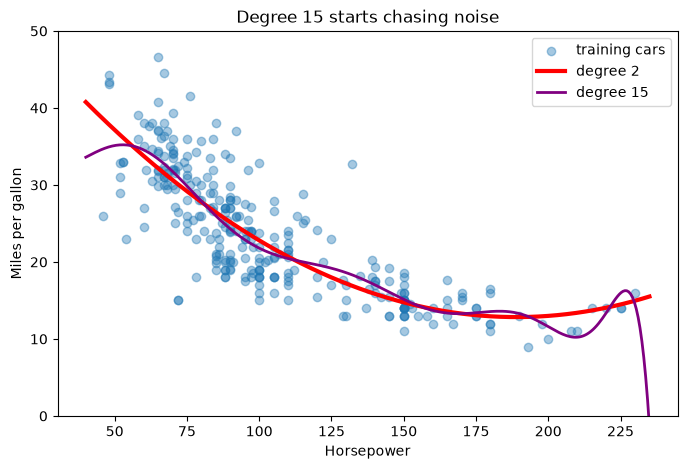

In [8]:
# What does a very high-degree model actually look like?
wiggly = poly_model(15).fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.4, label="training cars")
plt.plot(xp, quad.predict(xp), "r", lw=3, label="degree 2")
plt.plot(xp, wiggly.predict(xp), "purple", lw=2, label="degree 15")
plt.ylim(0, 50)
plt.xlabel("Horsepower"); plt.ylabel("Miles per gallon"); plt.legend()
plt.title("Degree 15 starts chasing noise")
plt.show()

**What this shows:**
* The big improvement is from degree 1 to degree 2. After that, test R² hardly changes (about 0.66 to 0.68).
* Training R² keeps going up with every extra degree, because a more flexible curve can always fit the training points a bit better.
* The degree-15 curve **wiggles**, especially at the edges where there are few cars. It is learning noise, not the real pattern. That is **overfitting**, and its test score starts to drop again.

Because higher degrees add complexity with almost no real gain, I choose **degree 2**. It is the simplest model
that captures the curve.

### 5. Using the model

In [9]:
final = make_pipeline(PolynomialFeatures(2), LinearRegression()).fit(X_train, y_train)   # no scaler, so the coefficients are readable
b0 = final[-1].intercept_
_, b1, b2 = final[-1].coef_
print(f"mpg = {b0:.2f} + ({b1:.4f} × hp) + ({b2:.6f} × hp²)")

for hp in [70, 100, 150, 200]:
    print(f"A {hp} hp car is predicted to do {final.predict([[hp]])[0]:.1f} mpg")

mpg = 57.78 + (-0.4757 × hp) + (0.001259 × hp²)
A 70 hp car is predicted to do 30.7 mpg
A 100 hp car is predicted to do 22.8 mpg
A 150 hp car is predicted to do 14.7 mpg
A 200 hp car is predicted to do 13.0 mpg


### Conclusion
* The fitted equation has a **negative** $hp$ term (MPG falls as power rises) and a small **positive** $hp^2$ term,
  which bends the curve back up so it levels off for big engines. This matches what we saw in the scatter plot.
* A 100 hp car is predicted at about 23 mpg, and a 200 hp car at about 13 mpg.
* A quadratic model explains about **66% of the variation** in fuel economy using only horsepower, on cars it has
  never seen. The remaining variation comes from things this model doesn't use, like weight, year and number of cylinders.
* The key lesson: **choose the degree using test data, not training data**. Training R² always improves with a higher degree, even when the model is getting worse.